In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2
from scipy.spatial.distance import mahalanobis

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.cluster import DBSCAN
from sklearn.svm import OneClassSVM

# Set visual style for plots
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

In [3]:
# Load the dataset
csv_path = "./data/Occupancy_Estimation.csv"
df = pd.read_csv(csv_path)

# Select only the numerical sensor features (exclude Date, Time, and target label)
feature_cols = [col for col in df.columns if col not in ["Date", "Time", "Room_Occupancy_Count"]]
X = df[feature_cols].copy()

# Standardize features (mean = 0, std = 1) - essential for distance and density methods
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Create a 2D PCA projection for visualizing outliers across methods
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

# DataFrame to store binary outlier flags (1 = Outlier, 0 = Inlier) for each method
outliers_df = pd.DataFrame(index=df.index)

print(f"Dataset loaded: {X.shape[0]} rows, {X.shape[1]} sensor features.")

Dataset loaded: 10129 rows, 16 sensor features.


Mahalanobis Distance Threshold (Chi2, p=0.001): 39.25
Mahalanobis Outliers Detected: 1423 (14.05%)


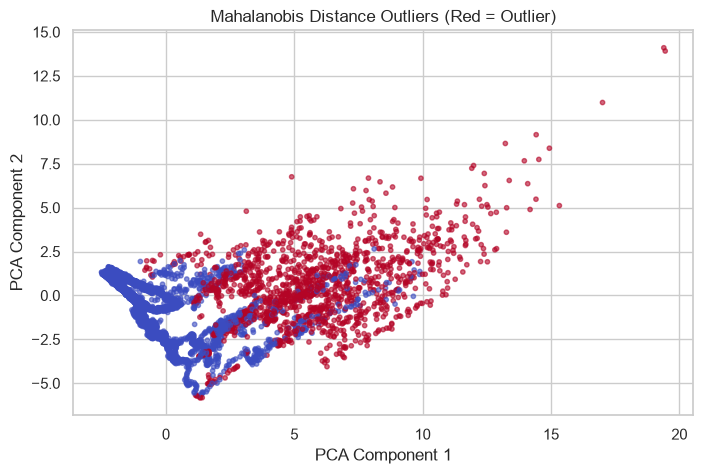

In [4]:
# Calculate mean vector and inverse covariance matrix (pseudo-inverse handles collinearity)
mean_vec = np.mean(X_scaled, axis=0)
cov_matrix = np.cov(X_scaled, rowvar=False)
inv_cov_matrix = np.linalg.pinv(cov_matrix)

# Compute squared Mahalanobis distance for every observation
diff = X_scaled - mean_vec
md_squared = np.sum(np.dot(diff, inv_cov_matrix) * diff, axis=1)

# Set cutoff threshold using Chi-Square distribution at 99.9% confidence (p = 0.001)
dof = X_scaled.shape[1]
threshold_md = chi2.ppf(0.999, dof)

# Flag outliers (1 = Outlier, 0 = Normal)
outliers_df["Mahalanobis"] = (md_squared > threshold_md).astype(int)

n_outliers_md = outliers_df["Mahalanobis"].sum()
print(f"Mahalanobis Distance Threshold (Chi2, p=0.001): {threshold_md:.2f}")
print(f"Mahalanobis Outliers Detected: {n_outliers_md} ({n_outliers_md / len(df) * 100:.2f}%)")

# Plot PCA projection of Mahalanobis Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Mahalanobis"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Mahalanobis Distance Outliers (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Isolation Forest Outliers Detected: 507 (5.01%)


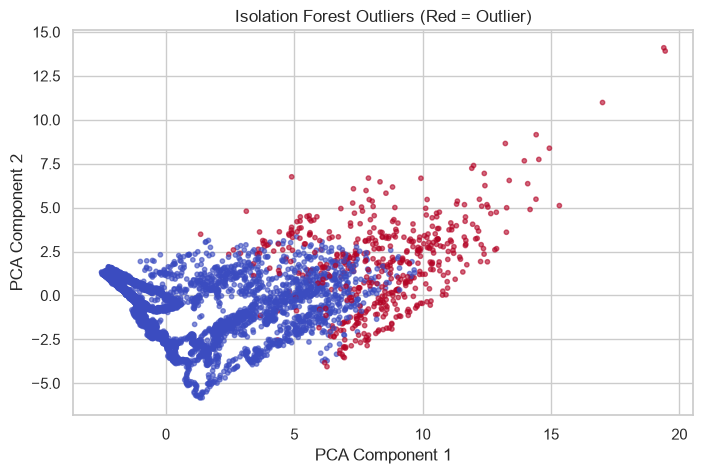

In [5]:
# Initialize and fit Isolation Forest (assuming ~5% contamination rate)
iso_forest = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

# fit_predict returns -1 for outliers and 1 for inliers
iso_preds = iso_forest.fit_predict(X_scaled)
outliers_df["Isolation_Forest"] = (iso_preds == -1).astype(int)

n_outliers_iso = outliers_df["Isolation_Forest"].sum()
print(f"Isolation Forest Outliers Detected: {n_outliers_iso} ({n_outliers_iso / len(df) * 100:.2f}%)")

# Plot PCA projection of Isolation Forest Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Isolation_Forest"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Isolation Forest Outliers (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

d:\0myGames\1\Machine-learning-University\.venv\Lib\site-packages\sklearn\neighbors\_lof.py:327: UserWarning: Duplicate values are leading to incorrect results. Increase the number of neighbors for more accurate results.
  warnings.warn(


LOF Outliers Detected: 506 (5.00%)


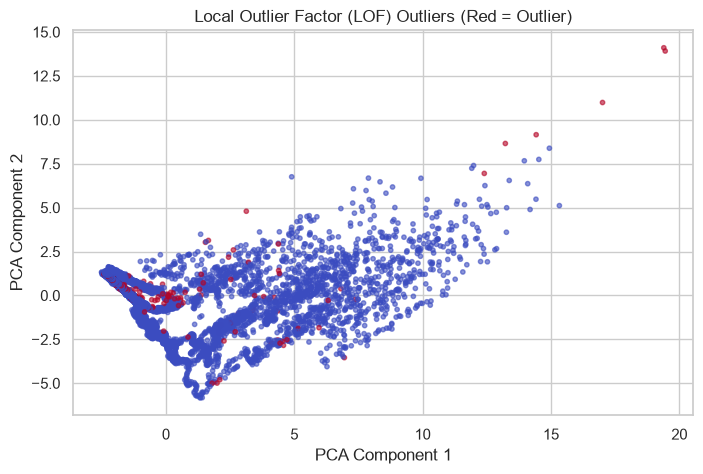

In [6]:
# Initialize and fit Local Outlier Factor
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    n_jobs=-1
)

# fit_predict returns -1 for outliers and 1 for inliers
lof_preds = lof.fit_predict(X_scaled)
outliers_df["LOF"] = (lof_preds == -1).astype(int)

n_outliers_lof = outliers_df["LOF"].sum()
print(f"LOF Outliers Detected: {n_outliers_lof} ({n_outliers_lof / len(df) * 100:.2f}%)")

# Plot PCA projection of LOF Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["LOF"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Local Outlier Factor (LOF) Outliers (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

DBSCAN Clusters Found: 30
DBSCAN Outliers (Noise Points) Detected: 726 (7.17%)


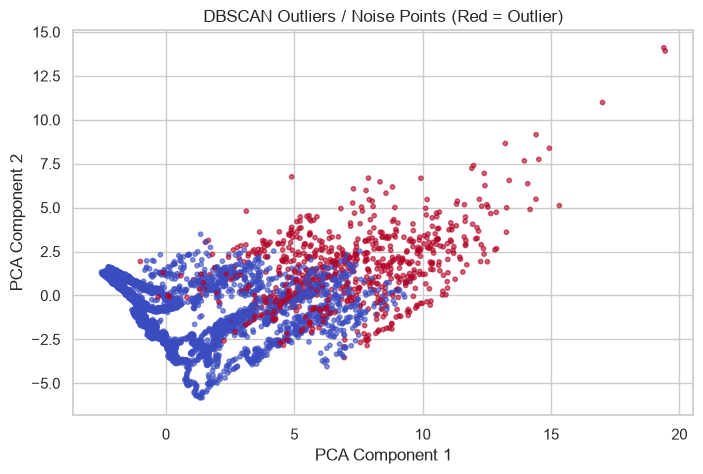

In [7]:
# Initialize and fit DBSCAN
# eps controls neighborhood radius; min_samples is minimum points required to form a dense region
dbscan = DBSCAN(eps=2.0, min_samples=10, n_jobs=-1)
dbscan_labels = dbscan.fit_predict(X_scaled)

# In DBSCAN, label -1 indicates noise (outliers)
outliers_df["DBSCAN"] = (dbscan_labels == -1).astype(int)

n_clusters = len(set(dbscan_labels)) - (1 if -1 in dbscan_labels else 0)
n_outliers_db = outliers_df["DBSCAN"].sum()
print(f"DBSCAN Clusters Found: {n_clusters}")
print(f"DBSCAN Outliers (Noise Points) Detected: {n_outliers_db} ({n_outliers_db / len(df) * 100:.2f}%)")

# Plot PCA projection of DBSCAN Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["DBSCAN"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("DBSCAN Outliers / Noise Points (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

One-Class SVM Outliers Detected: 511 (5.04%)


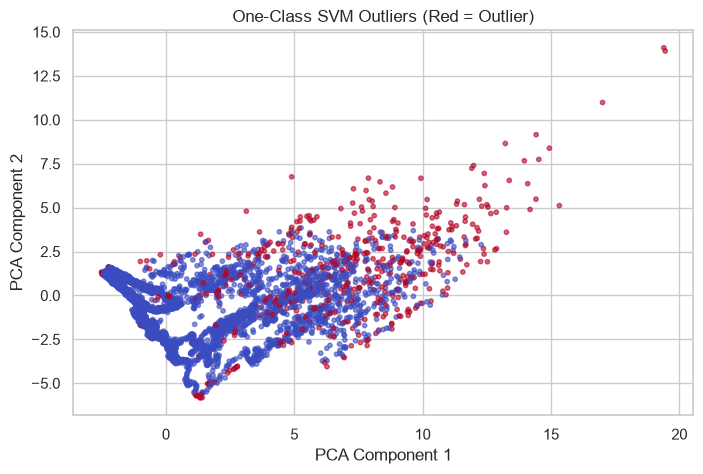

In [8]:
# Initialize and fit One-Class SVM (nu=0.05 sets an upper bound of 5% on training errors/outliers)
oc_svm = OneClassSVM(kernel="rbf", gamma="scale", nu=0.05)

svm_preds = oc_svm.fit_predict(X_scaled)
outliers_df["OneClass_SVM"] = (svm_preds == -1).astype(int)

n_outliers_svm = outliers_df["OneClass_SVM"].sum()
print(f"One-Class SVM Outliers Detected: {n_outliers_svm} ({n_outliers_svm / len(df) * 100:.2f}%)")

# Plot PCA projection of One-Class SVM Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["OneClass_SVM"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("One-Class SVM Outliers (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

Z-Score (|Z| > 3.5) Outliers Detected: 702 (6.93%)


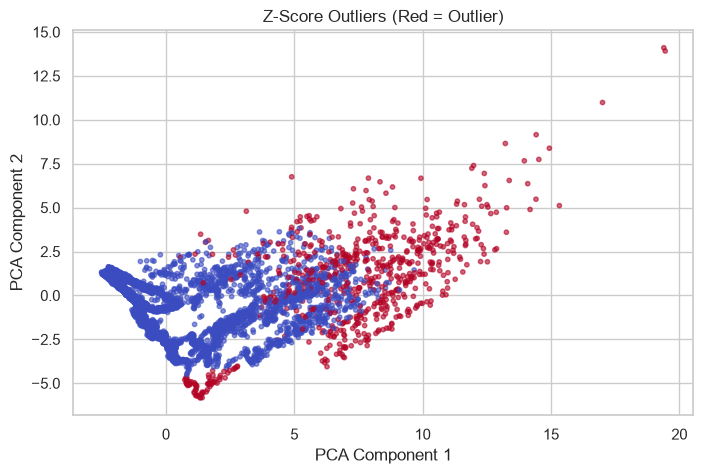

In [9]:
# Since X_scaled is already standardized (Z-scores), check if any feature has |Z| > 3.5
z_threshold = 3.5
outliers_df["Z_Score"] = (np.abs(X_scaled) > z_threshold).any(axis=1).astype(int)

n_outliers_z = outliers_df["Z_Score"].sum()
print(f"Z-Score (|Z| > {z_threshold}) Outliers Detected: {n_outliers_z} ({n_outliers_z / len(df) * 100:.2f}%)")

# Plot PCA projection of Z-Score Outliers
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=outliers_df["Z_Score"], cmap="coolwarm", s=10, alpha=0.6)
plt.title("Z-Score Outliers (Red = Outlier)")
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.show()

=== OUTLIER DETECTION SUMMARY BY METHOD ===


,Outlier_Count,Percentage (%)
Mahalanobis,1423,14.05
DBSCAN,726,7.17
Z_Score,702,6.93
OneClass_SVM,511,5.04
Isolation_Forest,507,5.01
LOF,506,5.00


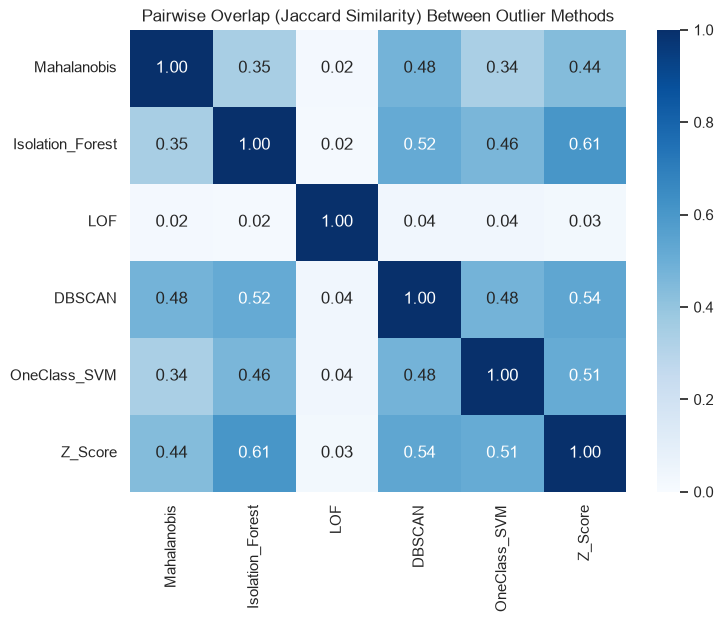


=== CONSENSUS COUNT (Number of Methods Flagging the Same Row) ===
Flagged by 0 method(s): 8158 rows (80.54%)
Flagged by 1 method(s): 1043 rows (10.30%)
Flagged by 2 method(s): 249 rows (2.46%)
Flagged by 3 method(s): 197 rows (1.94%)
Flagged by 4 method(s): 181 rows (1.79%)
Flagged by 5 method(s): 287 rows (2.83%)
Flagged by 6 method(s): 14 rows (0.14%)

High-confidence outliers (flagged by all 6 methods): 14 rows


,Date,Time,S1_Temp,S2_Temp,S3_Temp,S4_Temp,S1_Light,S2_Light,S3_Light,S4_Light,S1_Sound,S2_Sound,S3_Sound,S4_Sound,S5_CO2,S5_CO2_Slope,S6_PIR,S7_PIR,Room_Occupancy_Count,Total_Methods_Flagged
10,2017/12/22,10:54:47,25.06,24.81,24.56,25.44,122,35,57,43,2.20,0.31,0.33,0.21,390,-0.276923,1,1,1,6
206,2017/12/22,12:37:56,25.81,28.81,25.38,26.13,160,243,215,66,2.04,0.62,3.64,3.40,675,1.623077,1,1,3,6
210,2017/12/22,12:39:58,25.81,29.00,25.38,26.06,159,243,224,67,3.47,3.34,1.72,3.40,690,2.057692,1,1,3,6
219,2017/12/22,13:09:35,25.94,28.06,25.50,26.13,163,249,229,70,0.53,0.31,0.25,3.40,815,5.719231,1,1,3,6
224,2017/12/22,13:12:08,25.94,28.19,25.50,26.13,162,247,228,70,0.79,0.81,1.36,1.84,835,8.096154,1,0,3,6


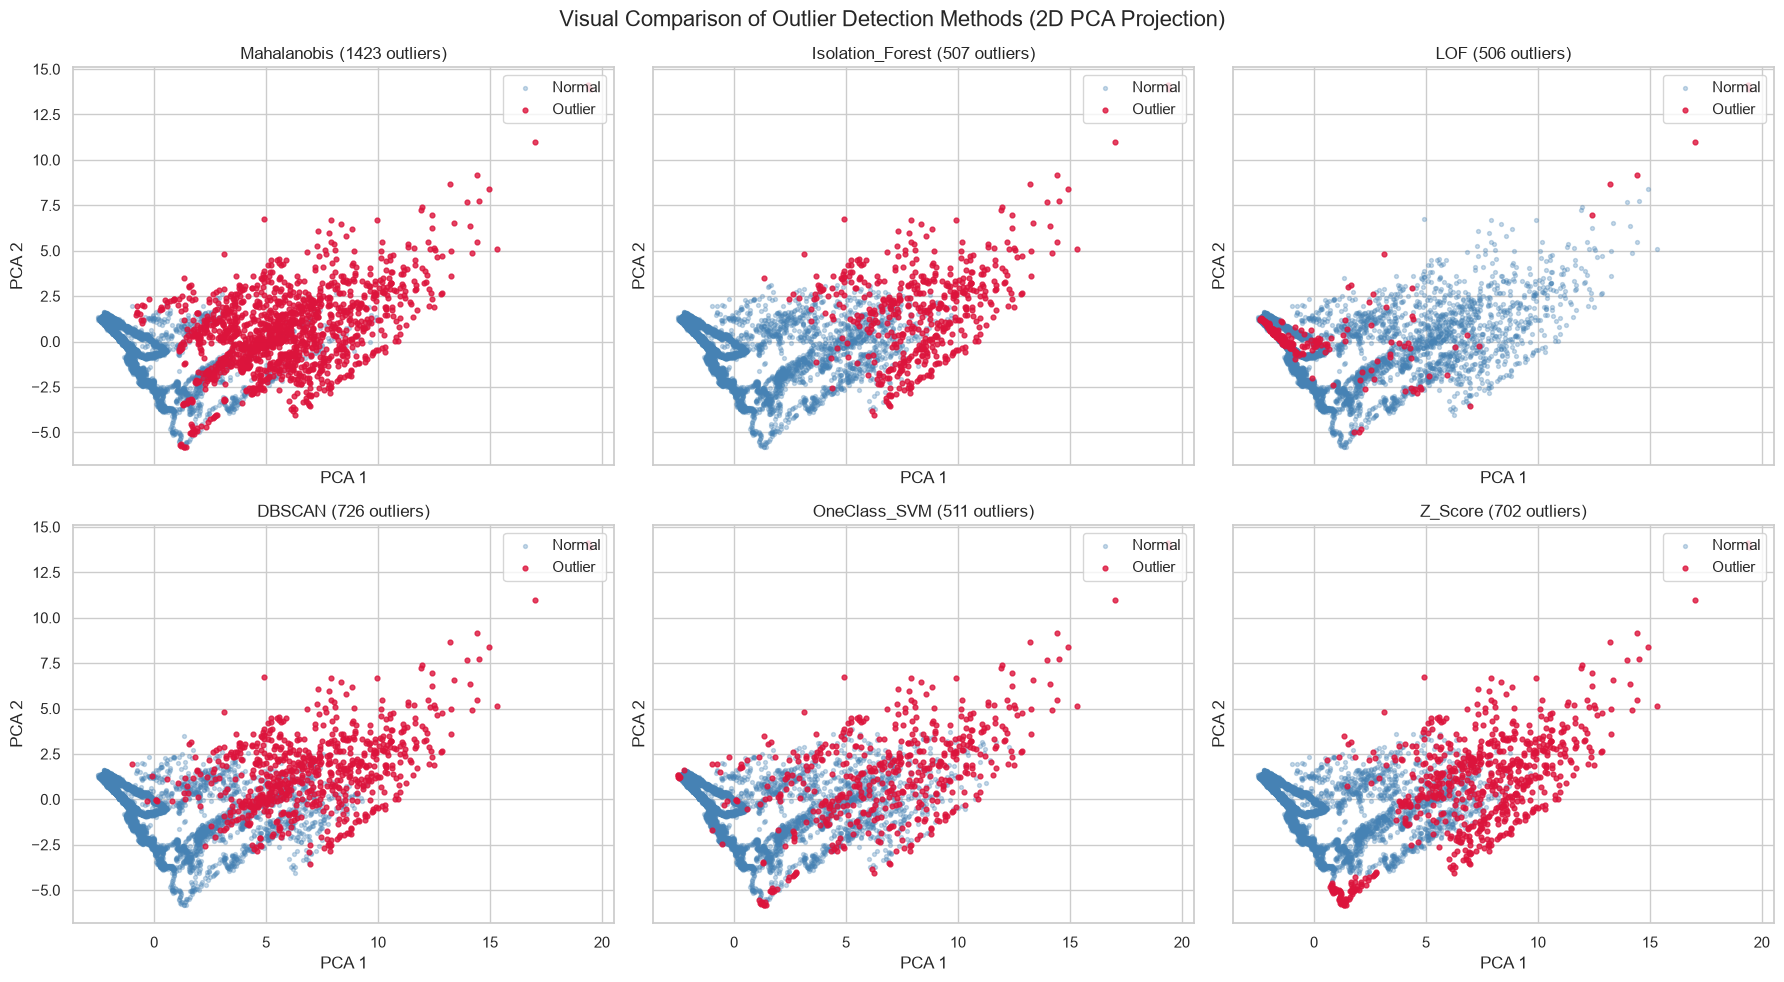

In [10]:
# 1. Summary Table of Outlier Counts and Percentages
summary_table = pd.DataFrame({
    "Outlier_Count": outliers_df.sum(),
    "Percentage (%)": (outliers_df.mean() * 100).round(2)
}).sort_values(by="Outlier_Count", ascending=False)

print("=== OUTLIER DETECTION SUMMARY BY METHOD ===")
display(summary_table)

# 2. Compute Pairwise Jaccard Similarity (Intersection over Union of detected outliers)
methods = outliers_df.columns
jaccard_matrix = pd.DataFrame(index=methods, columns=methods, dtype=float)

for m1 in methods:
    for m2 in methods:
        intersection = np.logical_and(outliers_df[m1], outliers_df[m2]).sum()
        union = np.logical_or(outliers_df[m1], outliers_df[m2]).sum()
        jaccard_matrix.loc[m1, m2] = intersection / union if union > 0 else 0.0

plt.figure(figsize=(8, 6))
sns.heatmap(jaccard_matrix, annot=True, cmap="Blues", fmt=".2f", vmin=0, vmax=1)
plt.title("Pairwise Overlap (Jaccard Similarity) Between Outlier Methods")
plt.show()

# 3. Consensus Analysis (How many methods agree on each row?)
df["Total_Methods_Flagged"] = outliers_df.sum(axis=1)
consensus_counts = df["Total_Methods_Flagged"].value_counts().sort_index()

print("\n=== CONSENSUS COUNT (Number of Methods Flagging the Same Row) ===")
for k, count in consensus_counts.items():
    print(f"Flagged by {k} method(s): {count} rows ({count / len(df) * 100:.2f}%)")

# Inspect high-confidence outliers flagged by all 6 methods
high_confidence_outliers = df[df["Total_Methods_Flagged"] == len(methods)]
print(f"\nHigh-confidence outliers (flagged by all {len(methods)} methods): {len(high_confidence_outliers)} rows")
display(high_confidence_outliers.head())

# 4. Side-by-Side 2x3 Visual Comparison in PCA Space
fig, axes = plt.subplots(2, 3, figsize=(18, 10), sharex=True, sharey=True)
axes = axes.flatten()

for idx, method in enumerate(methods):
    ax = axes[idx]
    inliers = outliers_df[method] == 0
    outliers = outliers_df[method] == 1
    
    ax.scatter(X_pca[inliers, 0], X_pca[inliers, 1], c="steelblue", s=8, alpha=0.3, label="Normal")
    ax.scatter(X_pca[outliers, 0], X_pca[outliers, 1], c="crimson", s=12, alpha=0.8, label="Outlier")
    ax.set_title(f"{method} ({outliers.sum()} outliers)")
    ax.set_xlabel("PCA 1")
    ax.set_ylabel("PCA 2")
    ax.legend(loc="upper right")

plt.suptitle("Visual Comparison of Outlier Detection Methods (2D PCA Projection)", fontsize=16)
plt.tight_layout()
plt.show()